# Ames Housing Price Prediction

This notebook builds a leakage-safe regression workflow for the Ames Housing dataset. It covers dataset understanding, manual and automated EDA, feature engineering, three preprocessing pipelines, tuned regression models, evaluation, interpretation, and reproducible report exports.

In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')
df = pd.read_csv('AmesHousing.csv', na_values=['NA'])
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('/', '_', regex=False)
df = df.drop(columns=['order', 'pid'], errors='ignore')
target = 'saleprice'
print('Shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'missing_%': (df.isna().mean() * 100).round(2)}).sort_values('missing', ascending=False).head(20))
display(df[target].describe().to_frame('saleprice'))
print('Numeric predictors:', df.select_dtypes(include=np.number).shape[1] - 1)
print('Categorical predictors:', df.select_dtypes(exclude=np.number).shape[1])

Shape: (2930, 80)
Duplicate rows: 0


,ms_subclass,ms_zoning,lot_frontage,lot_area,street,alley,lot_shape,land_contour,utilities,lot_config,...,pool_area,pool_qc,fence,misc_feature,misc_val,mo_sold,yr_sold,sale_type,sale_condition,saleprice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


,dtype,missing,missing_%
pool_qc,object,2917,99.56
misc_feature,object,2824,96.38
alley,object,2732,93.24
fence,object,2358,80.48
mas_vnr_type,object,1775,60.58
fireplace_qu,object,1422,48.53
lot_frontage,float64,490,16.72
garage_yr_blt,float64,159,5.43
garage_qual,object,159,5.43
garage_cond,object,159,5.43


,saleprice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


Numeric predictors: 36
Categorical predictors: 43


## Manual EDA

SalePrice is expected to be right-skewed, so the model will use log1p(SalePrice) and convert predictions back to dollars for evaluation. The plots inspect distributions, outliers, correlations, and relationships with price.

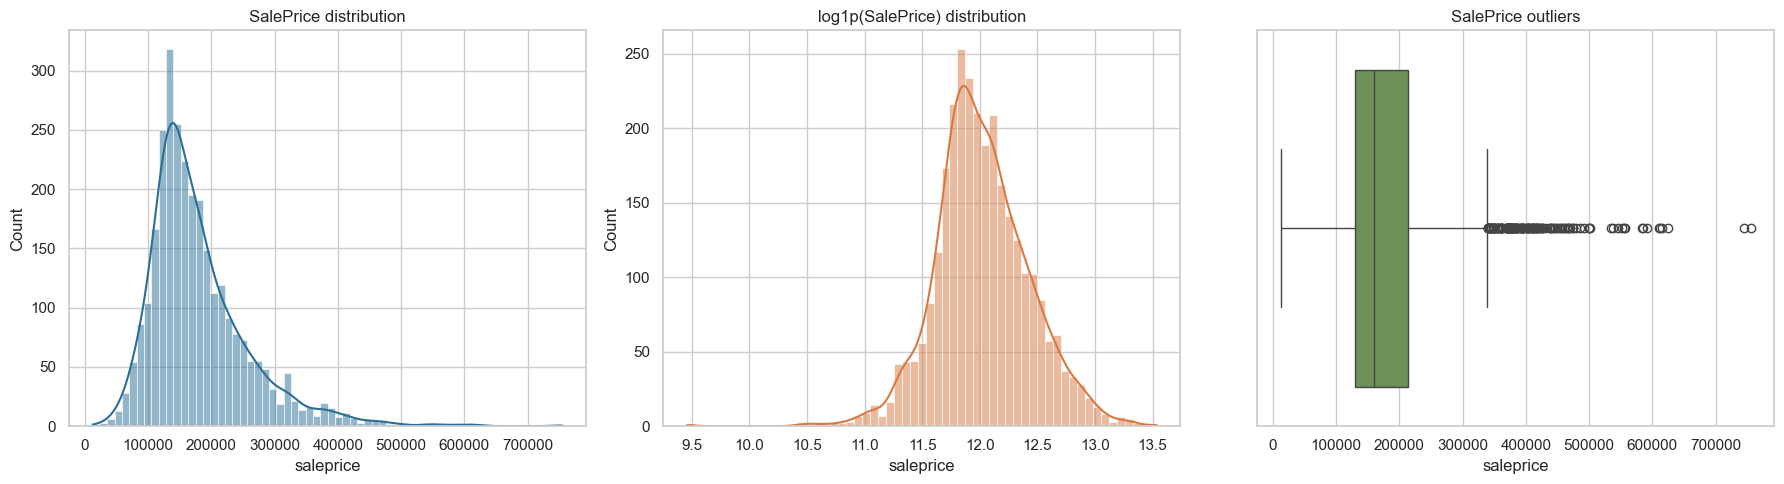

,correlation_with_saleprice
saleprice,1.000000
overall_qual,0.799262
gr_liv_area,0.706780
garage_cars,0.647877
garage_area,0.640401
total_bsmt_sf,0.632280
1st_flr_sf,0.621676
year_built,0.558426
full_bath,0.545604
year_remod_add,0.532974


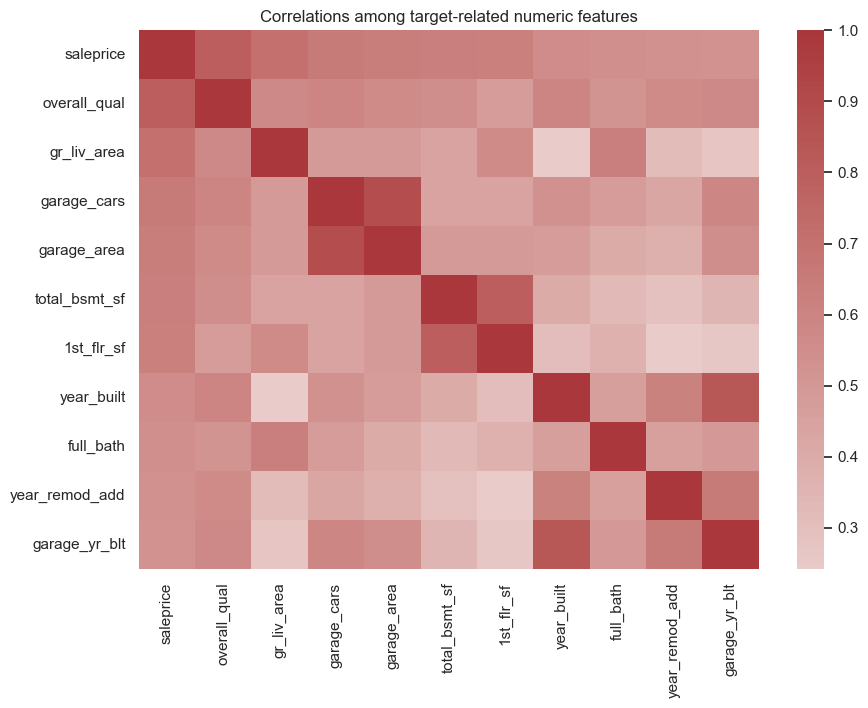

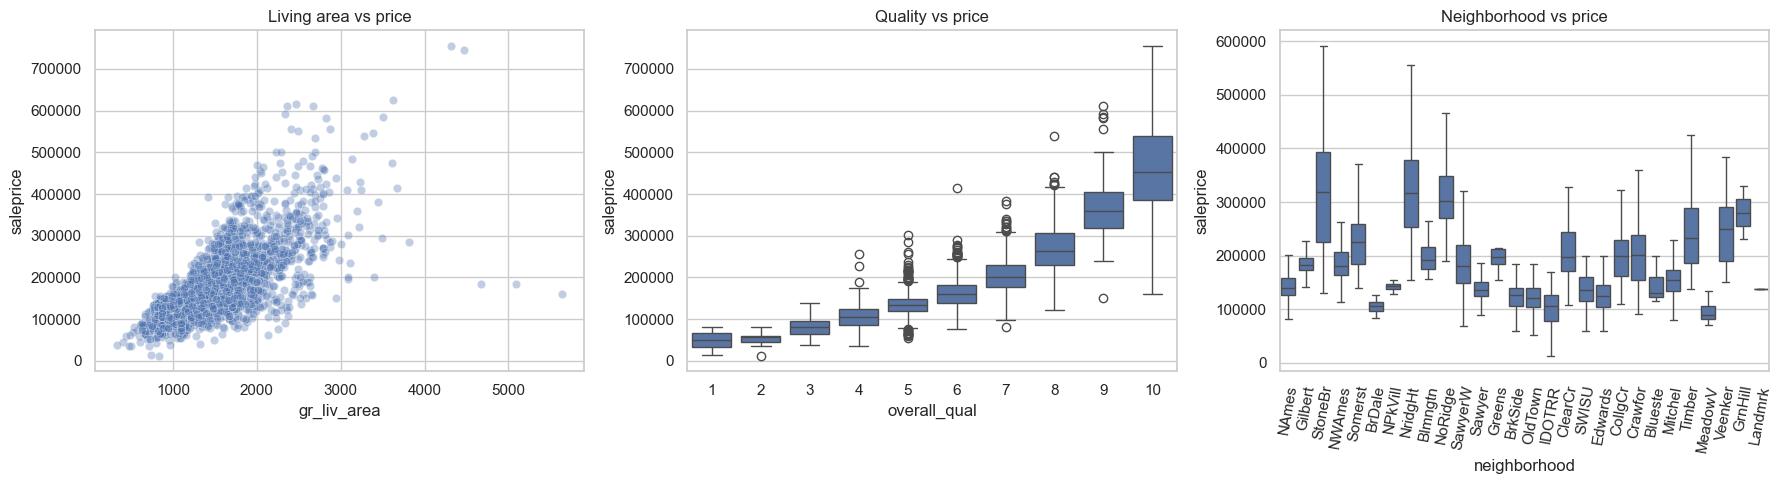

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df[target], kde=True, ax=axes[0], color='#2a6f97')
axes[0].set_title('SalePrice distribution')
sns.histplot(np.log1p(df[target]), kde=True, ax=axes[1], color='#d97941')
axes[1].set_title('log1p(SalePrice) distribution')
sns.boxplot(x=df[target], ax=axes[2], color='#6a994e')
axes[2].set_title('SalePrice outliers')
plt.tight_layout(); plt.show()

numeric_corr = df.select_dtypes(include=np.number).corr()[target].sort_values(ascending=False)
display(numeric_corr.head(12).to_frame('correlation_with_saleprice'))
top_corr = numeric_corr.abs().sort_values(ascending=False).head(11).index
plt.figure(figsize=(10, 7)); sns.heatmap(df[top_corr].corr(), cmap='vlag', center=0)
plt.title('Correlations among target-related numeric features'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x='gr_liv_area', y=target, alpha=.35, ax=axes[0])
sns.boxplot(data=df, x='overall_qual', y=target, ax=axes[1])
sns.boxplot(data=df, x='neighborhood', y=target, ax=axes[2], showfliers=False)
axes[2].tick_params(axis='x', rotation=80)
axes[0].set_title('Living area vs price'); axes[1].set_title('Quality vs price'); axes[2].set_title('Neighborhood vs price')
plt.tight_layout(); plt.show()

## Automated EDA

The ydata-profiling report supplies a systematic audit of distributions, missingness, correlations, and warnings. Manual EDA highlights the domain relationships; automated EDA checks every field consistently.

In [3]:
from ydata_profiling import ProfileReport
profile = ProfileReport(df, title='Ames Housing Automated EDA', explorative=True, minimal=True)
profile.to_file('ames_housing_profile.html')
print('Saved ames_housing_profile.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 28.81it/s]

Saved ames_housing_profile.html


## Preprocessing and data splits

Numeric variables use median imputation and StandardScaler because SVR is sensitive to feature magnitude. Nominal variables use most-frequent imputation and one-hot encoding. Ordered quality variables use explicit ordinal encoding. Every transformation is fitted inside the ColumnTransformer to prevent leakage.

## Model development and tuning

SVR `C` controls the penalty for errors; larger values fit the training data more closely. `gamma` controls local influence for nonlinear kernels; larger values are more flexible. The kernel controls shape, and polynomial `degree` controls polynomial complexity. A reduced grid keeps the workflow practical.

In [9]:
ordinal_orders = {
    'exter_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'exter_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'bsmt_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'heating_qc': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'kitchen_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'fireplace_qu': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'garage_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'garage_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'pool_qc': ['Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_exposure': ['No', 'Mn', 'Av', 'Gd'], 'bsmtfin_type_1': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'bsmtfin_type_2': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], 'functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'garage_finish': ['Unf', 'RFn', 'Fin'], 'paved_drive': ['N', 'P', 'Y']
}
ordinal_features = [c for c in ordinal_orders if c in df.columns]
categorical_features = df.drop(columns=target).select_dtypes(exclude=np.number).columns.tolist()
nominal_features = [c for c in categorical_features if c not in ordinal_features]
numeric_features = df.drop(columns=target).select_dtypes(include=np.number).columns.tolist()
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
nominal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
ordinal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=[ordinal_orders[c] for c in ordinal_features], handle_unknown='use_encoded_value', unknown_value=-1))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_features), ('nominal', nominal_pipeline, nominal_features), ('ordinal', ordinal_pipeline, ordinal_features)], remainder='drop', verbose_feature_names_out=False)
X = df.drop(columns=target)
y = np.log1p(df[target])
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=RANDOM_STATE)
print(f'{len(numeric_features)} numeric, {len(nominal_features)} nominal, {len(ordinal_features)} ordinal features')
print('Train/validation/test:', X_train.shape, X_valid.shape, X_test.shape)

36 numeric, 27 nominal, 16 ordinal features
Train/validation/test: (2051, 79) (439, 79) (440, 79)


In [5]:
svr_pipeline = Pipeline([('preprocess', preprocessor), ('model', SVR())])
ridge_pipeline = Pipeline([('preprocess', preprocessor), ('model', Ridge())])
svr_grid = {'model__C': [10, 100], 'model__kernel': ['rbf', 'poly'], 'model__gamma': ['scale', 0.01], 'model__degree': [2, 3]}
ridge_grid = {'model__alpha': [1, 10, 100]}
svr_search = GridSearchCV(svr_pipeline, svr_grid, scoring='neg_root_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
ridge_search = GridSearchCV(ridge_pipeline, ridge_grid, scoring='neg_root_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
svr_search.fit(X_train, y_train)
ridge_search.fit(X_train, y_train)
print('Best SVR:', svr_search.best_params_, 'CV RMSE:', -svr_search.best_score_)
print('Best Ridge:', ridge_search.best_params_, 'CV RMSE:', -ridge_search.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best SVR: {'model__C': 10, 'model__degree': 2, 'model__gamma': 'scale', 'model__kernel': 'rbf'} CV RMSE: 0.13692692993026018
Best Ridge: {'model__alpha': 10} CV RMSE: 0.1422209692395431


## Evaluation and comparison

In [7]:
def evaluate_model(name, estimator, X_part, y_log, split):
    pred_log = estimator.predict(X_part)
    actual = np.expm1(y_log)
    predicted = np.maximum(0, np.expm1(pred_log))
    mse = mean_squared_error(actual, predicted)
    return {'model': name, 'split': split, 'MAE': mean_absolute_error(actual, predicted), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(actual, predicted)}

results = []
for name, estimator in [('SVR', svr_search.best_estimator_), ('Ridge', ridge_search.best_estimator_)]:
    for split, X_part, y_part in [('Train', X_train, y_train), ('Validation', X_valid, y_valid), ('Test', X_test, y_test)]:
        results.append(evaluate_model(name, estimator, X_part, y_part, split))
results_df = pd.DataFrame(results)
display(results_df.round(2))
display(results_df.pivot(index='model', columns='split', values='RMSE').round(2))
best_name = results_df.query("split == 'Validation'").sort_values('RMSE').iloc[0]['model']
print(f'Recommended model based on validation RMSE: {best_name}')
print('A large train-validation gap suggests overfitting; similar errors with low R2 suggest underfitting.')

,model,split,MAE,MSE,RMSE,R2
0,SVR,Train,10664.62,1.848845e+08,13597.22,0.97
1,SVR,Validation,14591.91,4.501675e+08,21217.15,0.93
2,SVR,Test,15054.94,8.345944e+08,28889.35,0.88
3,Ridge,Train,13786.87,5.462898e+08,23372.84,0.91
4,Ridge,Validation,14394.77,4.486039e+08,21180.27,0.93
5,Ridge,Test,16309.15,1.241163e+09,35230.14,0.83


split,Test,Train,Validation
model,,,
Ridge,35230.14,23372.84,21180.27
SVR,28889.35,13597.22,21217.15


Recommended model based on validation RMSE: Ridge
A large train-validation gap suggests overfitting; similar errors with low R2 suggest underfitting.


## Interpretation and final report export

,absolute_effect
roof_matl_ClyTile,0.139067
misc_feature_Gar2,0.106597
neighborhood_MeadowV,0.097037
misc_feature_Elev,0.094845
neighborhood_NridgHt,0.090879
overall_qual,0.089534
neighborhood_Crawfor,0.084032
neighborhood_GrnHill,0.083455
ms_zoning_A (agr),0.076847
sale_condition_Abnorml,0.076560


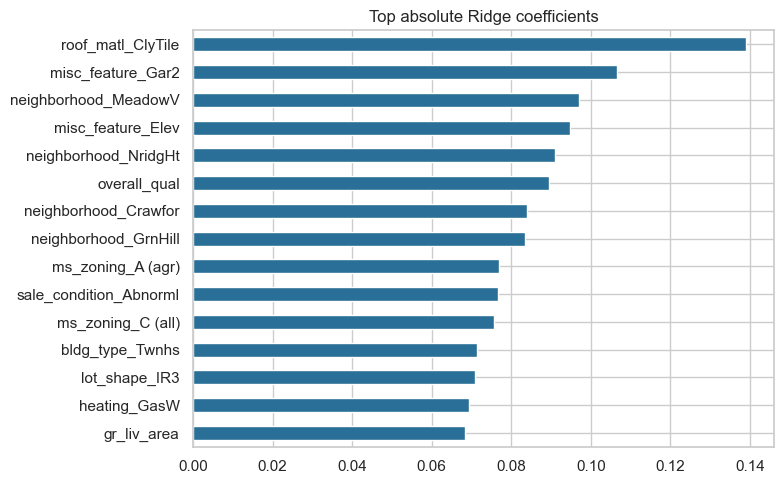

Saved ames_housing_final_report.pdf


In [8]:
best_estimator = svr_search.best_estimator_ if best_name == 'SVR' else ridge_search.best_estimator_
feature_names = best_estimator.named_steps['preprocess'].get_feature_names_out()
model = best_estimator.named_steps['model']
if hasattr(model, 'coef_'):
    importance = pd.Series(np.abs(model.coef_), index=feature_names).sort_values(ascending=False).head(15)
    display(importance.to_frame('absolute_effect'))
    importance.sort_values().plot.barh(figsize=(8, 5), color='#2a6f97', title='Top absolute Ridge coefficients')
    plt.tight_layout(); plt.show()
else:
    print('SVR feature importance is not directly available; use the Ridge coefficients as the interpretable companion model.')

from matplotlib.backends.backend_pdf import PdfPages
with PdfPages('ames_housing_final_report.pdf') as pdf:
    fig = plt.figure(figsize=(8.27, 11.69)); plt.axis('off')
    text = f'''Ames Housing Price Prediction\n\nDataset: {len(df):,} rows and {df.shape[1] - 1} predictors.\nTarget: SalePrice; trained on log1p(SalePrice) and converted back to dollars for metrics.\n\nPreprocessing\n- Median imputation and StandardScaler for numeric features.\n- One-hot encoding for nominal categories.\n- Explicit ordinal encoding for ordered quality/rating categories.\n- All transformations are inside ColumnTransformer pipelines.\n\nModel comparison\n{results_df.round(1).to_string(index=False)}\n\nRecommendation\n{best_name} is selected using validation RMSE. Compare train versus validation RMSE for overfitting; the held-out test row is the final unbiased estimate.\n\nEDA summary\nSalePrice is right-skewed; living area and overall quality show strong positive relationships with price. Outliers and missingness were audited manually and with ydata-profiling.'''
    fig.text(.08, .94, text, va='top', ha='left', fontsize=9, family='DejaVu Sans')
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(8.27, 5.5))
    sns.scatterplot(data=df, x='gr_liv_area', y=target, alpha=.3, ax=axes[0]); axes[0].set_title('Living area vs SalePrice')
    sns.boxplot(data=df, x='overall_qual', y=target, ax=axes[1]); axes[1].set_title('Overall quality vs SalePrice')
    plt.tight_layout(); pdf.savefig(fig); plt.close(fig)
print('Saved ames_housing_final_report.pdf')

## Reproducibility and deliverables

Generated files: `ames_housing_profile.html` (automated EDA) and `ames_housing_final_report.pdf` (compact report). Upload this notebook to Colab with the CSV and update the path if the data is stored in Drive.

In [4]:
ordinal_orders = {
    'exter_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'exter_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'bsmt_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'heating_qc': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'kitchen_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'fireplace_qu': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'garage_qual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'garage_cond': ['Po', 'Fa', 'TA', 'Gd', 'Ex'], 'pool_qc': ['Fa', 'TA', 'Gd', 'Ex'],
    'bsmt_exposure': ['No', 'Mn', 'Av', 'Gd'], 'bsmtfin_type_1': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'bsmtfin_type_2': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], 'functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'garage_finish': ['Unf', 'RFn', 'Fin'], 'paved_drive': ['N', 'P', 'Y']
}
ordinal_features = [c for c in ordinal_orders if c in df.columns]
categorical_features = df.drop(columns=target).select_dtypes(exclude=np.number).columns.tolist()
nominal_features = [c for c in categorical_features if c not in ordinal_features]
numeric_features = df.drop(columns=target).select_dtypes(include=np.number).columns.tolist()
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
nominal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
ordinal_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=[ordinal_orders[c] for c in ordinal_features], handle_unknown='use_encoded_value', unknown_value=-1))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_features), ('nominal', nominal_pipeline, nominal_features), ('ordinal', ordinal_pipeline, ordinal_features)], remainder='drop', verbose_feature_names_out=False)
X = df.drop(columns=target)
y = np.log1p(df[target])
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=RANDOM_STATE)
print(f'{len(numeric_features)} numeric, {len(nominal_features)} nominal, {len(ordinal_features)} ordinal features')
print('Train/validation/test:', X_train.shape, X_valid.shape, X_test.shape)

36 numeric, 27 nominal, 16 ordinal features
Train/validation/test: (2051, 79) (439, 79) (440, 79)
